<a href="https://colab.research.google.com/github/soumaya-lamrhari/customer-conversion-prediction/blob/main/notebooks/4_model_explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Explainability

## Objective

After evaluating the XGBoost model, the next step is to understand what is driving its predictions.

In this notebook, I use SHAP to identify the features that have the strongest influence on conversion predictions and understand how they affect the model’s output.

## Setup

In [1]:
!pip install -q ucimlrepo xgboost shap

import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier


# Load the Bank Marketing dataset
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features.copy()
y = bank_marketing.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (45211, 16)
Target shape: (45211, 1)


## Data Preparation

In [2]:
# Apply the same preprocessing decisions used during model development
X = X.drop(columns=["duration"])

X["poutcome"] = X["poutcome"].fillna("no_previous_contact")
X["contact"] = X["contact"].fillna("unknown")
X["job"] = X["job"].fillna("unknown")
X["education"] = X["education"].fillna("unknown")

X = X.rename(columns={"day_of_week": "day_of_month"})

# Convert the target to binary values
y = y["y"].map({"yes": 1, "no": 0})

print("Features shape:", X.shape)
print("Missing values:", X.isna().sum().sum())
print("Conversion rate:", round(y.mean() * 100, 2), "%")

Features shape: (45211, 15)
Missing values: 0
Conversion rate: 11.7 %


In [3]:
# Use the same split as the modeling notebook
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (36168, 15)
Test set: (9043, 15)


## Final XGBoost Model

I recreate the final XGBoost model using the same preprocessing steps and parameters from the modeling notebook. The model is trained on the full training set so I can use SHAP to understand what is driving its predictions.

In [4]:
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'balance', 'day_of_month', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [5]:
# Encode categorical features and keep numerical features unchanged
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

In [6]:
# Create the final XGBoost pipeline
xgb_model = Pipeline(
    steps=[
        ("preprocessor", xgb_preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            random_state=42,
            eval_metric="logloss"
        ))
    ]
)

In [7]:
# Train the final model on the full training set
_ = xgb_model.fit(X_train, y_train)

## SHAP Analysis

I use SHAP to understand which features have the strongest influence on the model’s conversion predictions and how they affect those predictions.

In [8]:
# Get the trained preprocessing and XGBoost components
trained_preprocessor = xgb_model.named_steps["preprocessor"]
trained_xgb = xgb_model.named_steps["classifier"]

# Transform the test data using the fitted preprocessor
X_test_transformed = trained_preprocessor.transform(X_test)

# Get the feature names after one-hot encoding so we can interpret the SHAP results
feature_names = trained_preprocessor.get_feature_names_out()

print("Transformed test shape:", X_test_transformed.shape)
print("Number of feature names:", len(feature_names))

Transformed test shape: (9043, 50)
Number of feature names: 50


In [9]:
import shap

# Create a SHAP explainer for the trained XGBoost model
explainer = shap.TreeExplainer(trained_xgb)

In [10]:
# Calculate SHAP values for the test customers
shap_values = explainer(X_test_transformed)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (9043, 50)


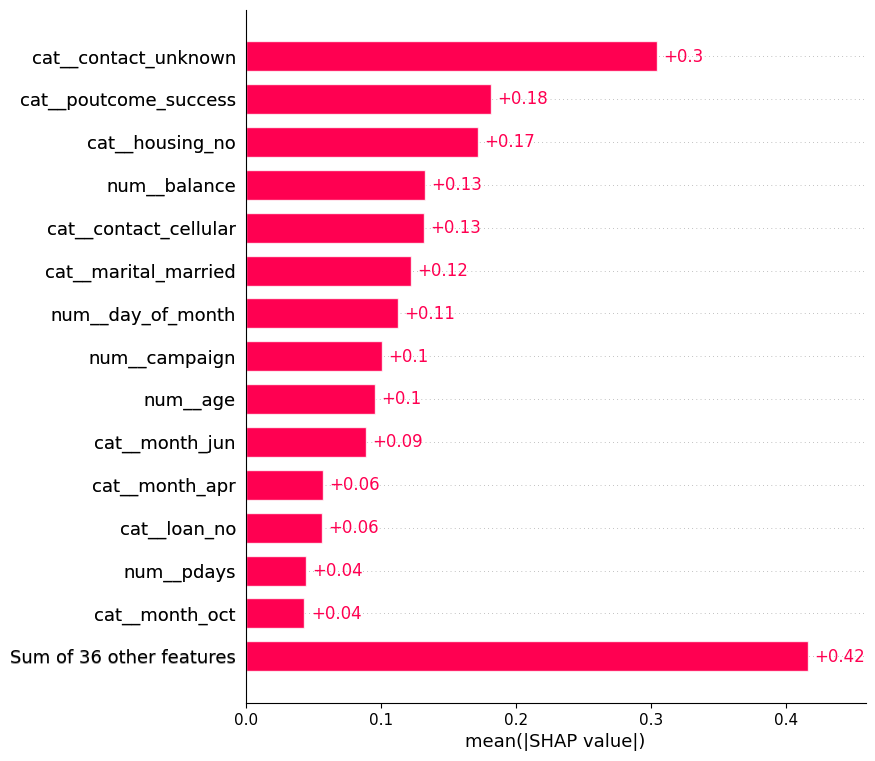

In [11]:
# Add the transformed feature names to the SHAP results
shap_values.feature_names = feature_names

# Show the most influential features across all test customers
shap.plots.bar(shap_values, max_display=15)

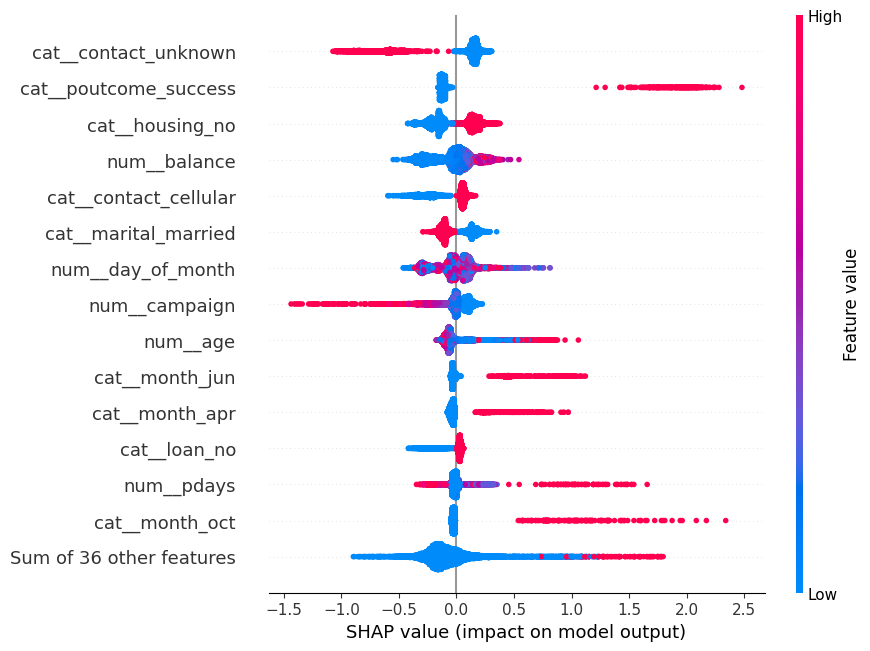

In [12]:
# Show both the importance and direction of feature effects
shap.plots.beeswarm(shap_values, max_display=15)

## SHAP Interpretation

The SHAP results show that previous campaign outcomes, contact information, housing loan status, account balance, and campaign activity are among the most influential features in the model.

Previous campaign success tends to push predictions toward conversion, while an unknown contact method tends to push predictions away from conversion. Higher account balances generally have a positive effect on conversion predictions, while a higher number of campaign contacts tends to have a negative effect.

These results describe patterns learned by the model and should not be interpreted as causal relationships.

## Feature-Level Analysis

To better understand how individual features affect the model’s predictions, I examine some of the most influential features identified by SHAP.

**Balance SHAP plot :**






In [13]:
# Find the position of the balance feature
balance_index = list(feature_names).index("num__balance")

print("Balance feature index:", balance_index)

Balance feature index: 45


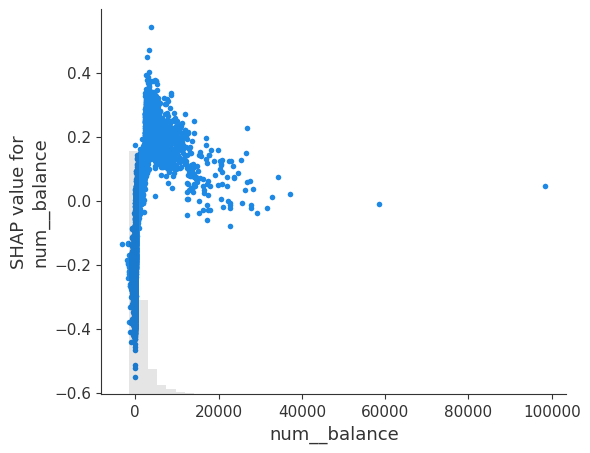

In [14]:
# Show how balance affects the model's predictions
shap.plots.scatter(shap_values[:, balance_index])

The SHAP dependence plot shows a nonlinear relationship between account balance and the model’s predictions. Low balances generally push predictions away from conversion, while moderate positive balances tend to push predictions toward conversion. The positive effect does not continue increasing for very high balances, although there are relatively few observations in that range.

**Campaign SHAP plot :**

Campaign feature index: 47


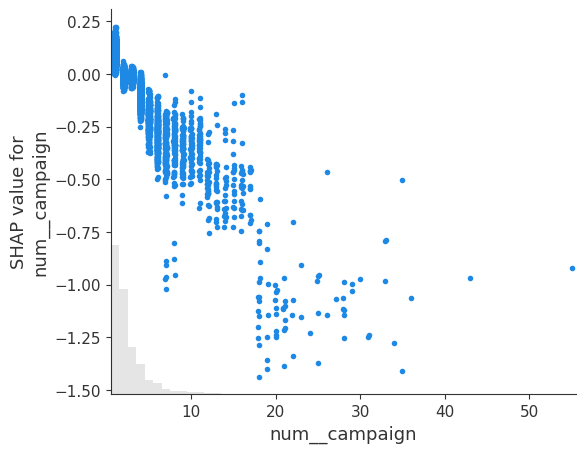

In [15]:
# Find the position of the campaign feature
campaign_index = list(feature_names).index("num__campaign")

print("Campaign feature index:", campaign_index)

# Show how the number of campaign contacts affects the model's predictions
shap.plots.scatter(shap_values[:, campaign_index])

The number of campaign contacts shows a clear negative relationship with the model’s conversion predictions. Customers with fewer contacts have a relatively neutral or positive contribution, while a higher number of contacts increasingly pushes predictions away from conversion.

This relationship represents a pattern learned by the model and should not be interpreted as evidence that additional contacts directly cause lower conversion.

## Individual Prediction Explanation

After analyzing the model’s overall feature importance, I examine an individual customer to understand which features contributed to their predicted conversion probability.

In [16]:
# Get conversion probabilities for the test customers
test_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Find the customer with the highest predicted conversion probability
high_prob_index = np.argmax(test_probabilities)

print("Customer position:", high_prob_index)
print("Predicted conversion probability:",
      round(test_probabilities[high_prob_index], 3))

Customer position: 2399
Predicted conversion probability: 0.93


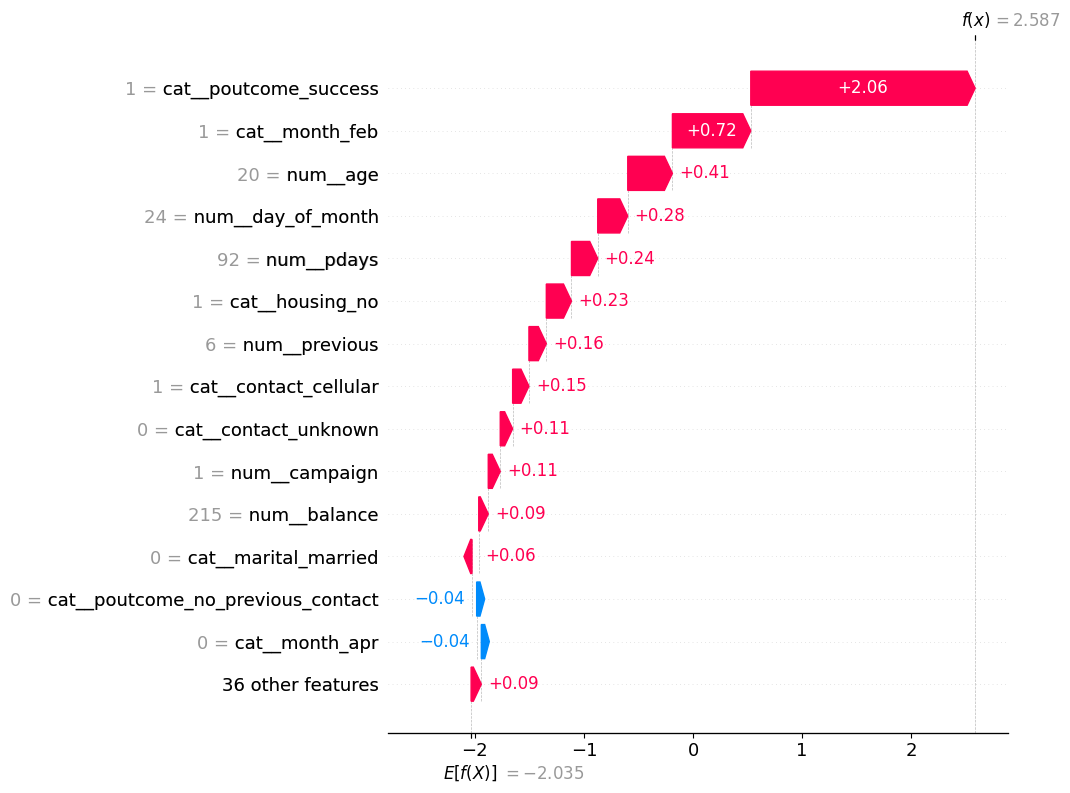

In [17]:
# Explain the prediction for the customer with the highest conversion probability
shap.plots.waterfall(shap_values[high_prob_index], max_display=15)

The selected customer received a 93% predicted probability of conversion. The strongest positive contributor was a successful outcome from a previous campaign. Other features, including the month of contact, age, previous campaign activity, and housing loan status, also contributed positively to the prediction.

This example shows how SHAP can be used to explain the factors behind an individual customer’s prediction rather than only looking at overall feature importance.

## Explainability Summary

SHAP was used to understand both the overall behavior of the XGBoost model and individual predictions.

The analysis showed that previous campaign outcomes, contact information, housing loan status, account balance, and campaign activity are among the most influential features in the model.

Previous campaign success strongly pushes predictions toward conversion, while an unknown contact method tends to push predictions away from conversion. Account balance shows a nonlinear relationship with the model’s predictions, while a higher number of campaign contacts generally has a negative effect.

The individual prediction analysis also showed how SHAP can explain why a specific customer receives a high conversion score by identifying the features that contributed most to that prediction.

These results describe patterns learned by the model and should not be interpreted as causal relationships.